In [36]:
import numpy as np 
import pandas as pd
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from catboost import CatBoostClassifier
import shap

/home/sunsun/miniconda3/envs/prescriptive_datascience/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
df = pd.read_csv('data/bank-additional-full.csv', sep=';')
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [8]:
df.isna().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

## Check Categorical

In [12]:
cat_col = df.select_dtypes(include='str')
for i in cat_col:
    print(f'',cat_col[i].value_counts(),"\n")

 job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64 

 marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64 

 education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64 

 default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64 

 housing
yes        21576
no         18622
unknown      990
Name: count, dtype: int64 

 loan
no         33950
yes         6248
unknown      990
Name: count, dtype: int64 

 contact
cellular     26144
telephone    15044
Nam

- There is class imbalance in y (target)
- There is a lot of unknown value, need to handle this

## Handling Numerical

In [14]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [15]:
def group_pdays(days):
    if days == -1:
        return 'never_contacted'
    elif days <= 10:
        return 'recently_contacted'
    else:
        return 'contacted_long_ago'

df['pdays_group'] = df['pdays'].apply(group_pdays)

df = df.drop('pdays', axis=1)

## Modelling

In [18]:
X = df.drop(['y', 'duration'], axis=1)
y = df['y']
y = y.map({'yes': 1, 'no': 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

In [19]:
poutcome_order = ['nonexistent', 'failure', 'success']
pdays_order = ['never_contacted', 'contacted_long_ago', 'recently_contacted']

ordinal_features = ['poutcome', 'pdays_group']
onehot_features = ['loan', 'default', 'housing', 'job', 'marital', 
                   'education', 'contact', 'month', 'day_of_week']

ordinal_transformer = OrdinalEncoder(categories=[poutcome_order, pdays_order])

onehot_transformer = OneHotEncoder(handle_unknown='ignore')
preprocessor = ColumnTransformer(
    transformers=[
        ('ord', ordinal_transformer, ordinal_features),
        ('onehot', onehot_transformer, onehot_features)
    ],
    remainder='passthrough'
)

In [20]:
count_no = (y_train == 0).sum()
count_yes = (y_train == 1).sum()
weight_ratio = count_no / count_yes

xgb_model = XGBClassifier(
    scale_pos_weight=weight_ratio, 
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])

final_pipeline.fit(X_train, y_train)

[04:18:38] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['age','job','marital',...,'euribor3m','nr.employed','pdays_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ord', ...), ('onehot', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, 

### Result (Baseline, without SMOTE & StratifiedKFold)

AUC-ROC Score: 0.7871
Macro F1 Score: 0.6872


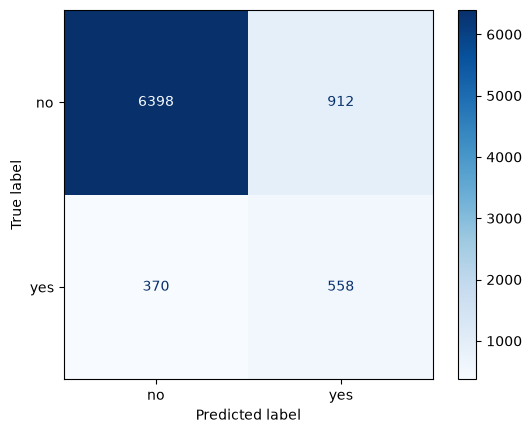

In [21]:
y_pred = final_pipeline.predict(X_test)

y_pred_proba = final_pipeline.predict_proba(X_test)[:, 1]

auc_roc = roc_auc_score(y_test, y_pred_proba)
macro_f1 = f1_score(y_test, y_pred, average='macro')
cm = confusion_matrix(y_test, y_pred)

print(f"AUC-ROC Score: {auc_roc:.4f}")
print(f"Macro F1 Score: {macro_f1:.4f}")

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['no', 'yes'])
disp.plot(cmap='Blues')
plt.show()

### SMOTE & StratifiedKFold

In [23]:
xgb_model = XGBClassifier(
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

smote_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', xgb_model)
])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [24]:
auc_roc_scores = []
macro_f1_scores = []

for train_index, test_index in skf.split(X, y):
    X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
    y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]
    
    smote_pipeline.fit(X_train_fold, y_train_fold)
    
    y_pred_fold = smote_pipeline.predict(X_test_fold)
    y_pred_proba_fold = smote_pipeline.predict_proba(X_test_fold)[:, 1]
    
    auc_roc_scores.append(roc_auc_score(y_test_fold, y_pred_proba_fold))
    macro_f1_scores.append(f1_score(y_test_fold, y_pred_fold, average='macro'))

print(f"Average AUC-ROC Score: {np.mean(auc_roc_scores):.4f}")
print(f"Average Macro F1 Score: {np.mean(macro_f1_scores):.4f}")

[04:26:55] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

[04:26:56] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

[04:26:58] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

[04:26:59] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

[04:27:01] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.



Average AUC-ROC Score: 0.7863
Average Macro F1 Score: 0.6696


Worst than baseline

### Trying Catboost

In [30]:
cat_features = ['job', 'marital', 'education', 'default', 'housing', 
                'loan', 'contact', 'month', 'day_of_week', 
                'poutcome', 'pdays_group']

X[cat_features] = X[cat_features].astype(str)

catboost = CatBoostClassifier(
    loss_function='Focal:focal_alpha=0.25;focal_gamma=2.0',
    cat_features=cat_features,
    iterations=500,
    random_seed=42,
    verbose=False
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [31]:
auc_roc_scores = []
macro_f1_scores = []

for train_index, test_index in skf.split(X, y):
    X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
    y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]
    
    catboost.fit(X_train_fold, y_train_fold)
    
    y_pred_fold = catboost.predict(X_test_fold)
    y_pred_proba_fold = catboost.predict_proba(X_test_fold)[:, 1]
    
    auc_roc_scores.append(roc_auc_score(y_test_fold, y_pred_proba_fold))
    macro_f1_scores.append(f1_score(y_test_fold, y_pred_fold, average='macro'))

print(f"Average AUC-ROC Score: {np.mean(auc_roc_scores):.4f}")
print(f"Average Macro F1 Score: {np.mean(macro_f1_scores):.4f}")

Average AUC-ROC Score: 0.7988
Average Macro F1 Score: 0.5517


### Baseline with StratifiedKFold

In [33]:
xgb_model = XGBClassifier(
    scale_pos_weight=weight_ratio, 
    random_state=42,
    eval_metric='logloss'
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


In [34]:
auc_roc_scores = []
macro_f1_scores = []

for train_index, test_index in skf.split(X, y):
    X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
    y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]
    
    final_pipeline.fit(X_train_fold, y_train_fold)
    
    y_pred_fold = final_pipeline.predict(X_test_fold)
    y_pred_proba_fold = final_pipeline.predict_proba(X_test_fold)[:, 1]
    
    auc_roc_scores.append(roc_auc_score(y_test_fold, y_pred_proba_fold))
    macro_f1_scores.append(f1_score(y_test_fold, y_pred_fold, average='macro'))

print(f"Average AUC-ROC Score: {np.mean(auc_roc_scores):.4f}")
print(f"Average Macro F1 Score: {np.mean(macro_f1_scores):.4f}")

[04:38:09] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

[04:38:09] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

[04:38:10] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

[04:38:11] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

[04:38:11] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.



Average AUC-ROC Score: 0.7715
Average Macro F1 Score: 0.6764


Slightly below baseline, but the model is more honest. Tell us how the model will work in real life

### Feature Selection SHAP

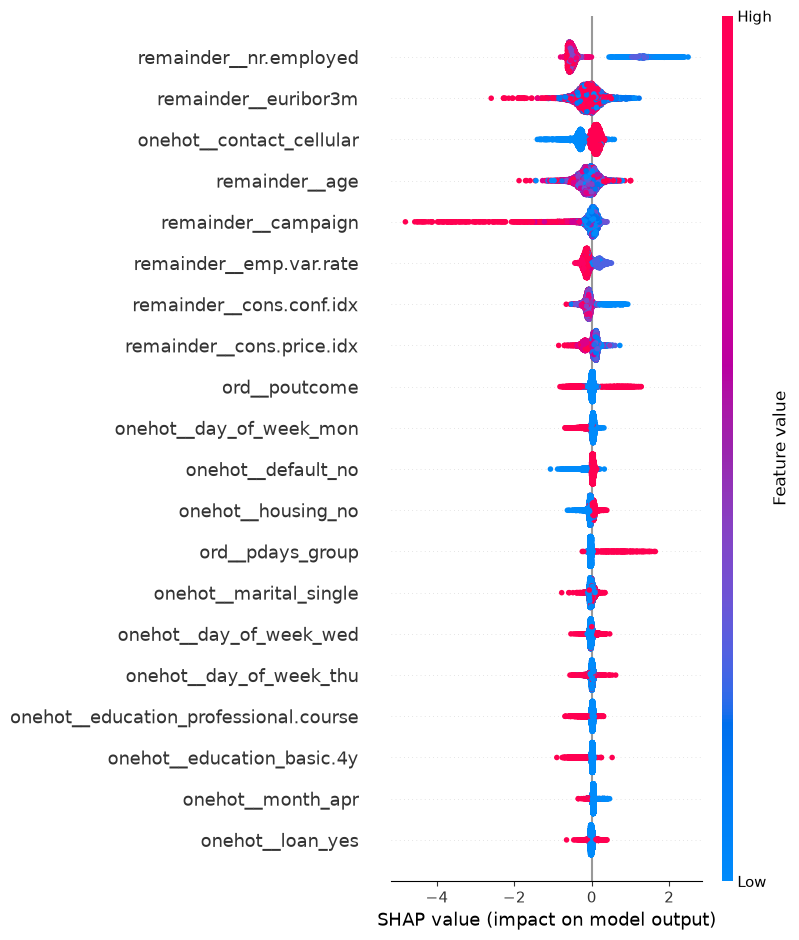

In [37]:
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

xgb_model.fit(X_train_transformed, y_train)

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_test_transformed)

shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names)

In [38]:
X_transformed_array = preprocessor.fit_transform(X)

feature_names = preprocessor.get_feature_names_out()

X_transformed = pd.DataFrame(X_transformed_array, columns=feature_names)

columns_to_drop = [
    'onehot__loan_yes',
    'onehot__month_apr',
    'onehot__education_basic.4y',
    'onehot__education_professional.course',
    'onehot__day_of_week_thu',
    'onehot__day_of_week_wed',
    'onehot__marital_single',
    'ord__pdays_group'
]

X_final = X_transformed.drop(columns=columns_to_drop)

xgb_model.fit(X_final, y)

final_probabilities = xgb_model.predict_proba(X_final)[:, 1]

X['probability'] = final_probabilities

print(X[['age', 'job', 'probability']].head())

   age        job  probability
0   56  housemaid     0.135121
1   57   services     0.086584
2   37   services     0.151785
3   40     admin.     0.147584
4   56   services     0.134595


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

auc_roc_scores = []
macro_f1_scores = []

for train_index, test_index in skf.split(X_final, y):
    X_train_fold, X_test_fold = X_final.iloc[train_index], X_final.iloc[test_index]
    y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]
    
    xgb_model.fit(X_train_fold, y_train_fold)
    
    y_pred_fold = xgb_model.predict(X_test_fold)
    y_pred_proba_fold = xgb_model.predict_proba(X_test_fold)[:, 1]
    
    auc_roc_scores.append(roc_auc_score(y_test_fold, y_pred_proba_fold))
    macro_f1_scores.append(f1_score(y_test_fold, y_pred_fold, average='macro'))

print(f"New Average AUC-ROC Score: {np.mean(auc_roc_scores):.4f}")
print(f"New Average Macro F1 Score: {np.mean(macro_f1_scores):.4f}")

New Average AUC-ROC Score: 0.7707
New Average Macro F1 Score: 0.6750


# Prescriptive